# 📰 Detekcija Lažnih Vijesti
### Predmet: Vještačka inteligencija

**Cilj projekta:** Razviti ML model koji automatski klasifikuje vijesti kao *fake* ili *real* na osnovu sadržaja teksta.

**Dataset:** Kaggle Fake and Real News Dataset (~44.000 vijesti)

**Pipeline:**
1. Učitavanje i spajanje dataseta
2. Eksplorativna analiza podataka (EDA)
3. Čišćenje i predobrada teksta
4. TF-IDF vektorizacija
5. Treniranje 3 modela (Logistic Regression, Naive Bayes, Random Forest)
6. Evaluacija i poređenje rezultata

## 1. Uvoz biblioteka

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from collections import Counter
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'fake': '#e74c3c', 'real': '#2ecc71'}

print('✅ Sve biblioteke uspješno uvezene.')

✅ Sve biblioteke uspješno uvezene.


## 2. Učitavanje i spajanje dataseta

In [3]:
# Učitavanje oba CSV fajla
fake_df = pd.read_csv("../data/Fake.csv")
true_df = pd.read_csv("../data/True.csv")

# Dodavanje labela
fake_df['label'] = 'fake'
true_df['label'] = 'real'

print(f'Fake vijesti:  {len(fake_df):,} zapisa')
print(f'Real vijesti:  {len(true_df):,} zapisa')

# Spajanje u jedan dataset i miješanje
df = pd.concat([fake_df, true_df], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\n✅ Spojeni dataset: {len(df):,} vijesti, {df.shape[1]} kolona')
df.head()

Fake vijesti:  23,481 zapisa
Real vijesti:  21,417 zapisa

✅ Spojeni dataset: 44,898 vijesti, 5 kolona


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",fake
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",real
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",real
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",fake
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",real


In [4]:
print('Informacije o datasetu:')
df.info()
print('\nNedostajuće vrijednosti:')
print(df.isnull().sum())
print('\nBroj duplikata:', df.duplicated().sum())

Informacije o datasetu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB

Nedostajuće vrijednosti:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Broj duplikata: 209


## 3. Eksplorativna analiza podataka (EDA)

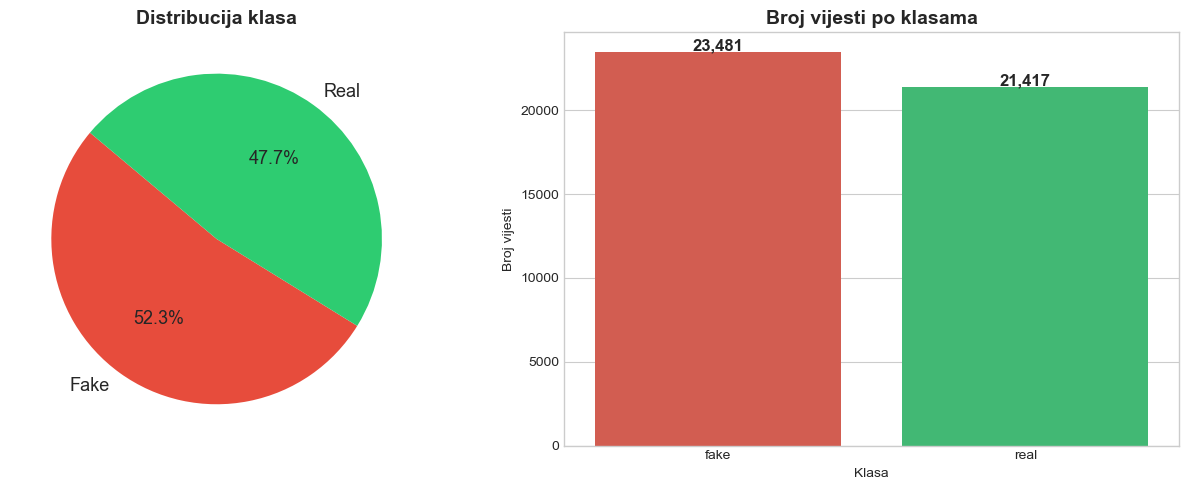

Distribucija:
label
fake    23481
real    21417
Name: count, dtype: int64

Procenti:
label
fake    52.3
real    47.7
Name: proportion, dtype: float64


In [5]:
# Distribucija klasa
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart
counts = df['label'].value_counts()
axes[0].pie(
    counts,
    labels=['Fake', 'Real'],
    colors=[COLORS['fake'], COLORS['real']],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 13}
)
axes[0].set_title('Distribucija klasa', fontsize=14, fontweight='bold')

# Count plot
sns.countplot(
    data=df, x='label',
    palette={'fake': COLORS['fake'], 'real': COLORS['real']},
    ax=axes[1]
)
axes[1].set_title('Broj vijesti po klasama', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Klasa'); axes[1].set_ylabel('Broj vijesti')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}',
                     (p.get_x() + p.get_width() / 2, p.get_height() + 100),
                     ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print('Distribucija:')
print(df['label'].value_counts())
print('\nProcenti:')
print(round(df['label'].value_counts(normalize=True) * 100, 2))

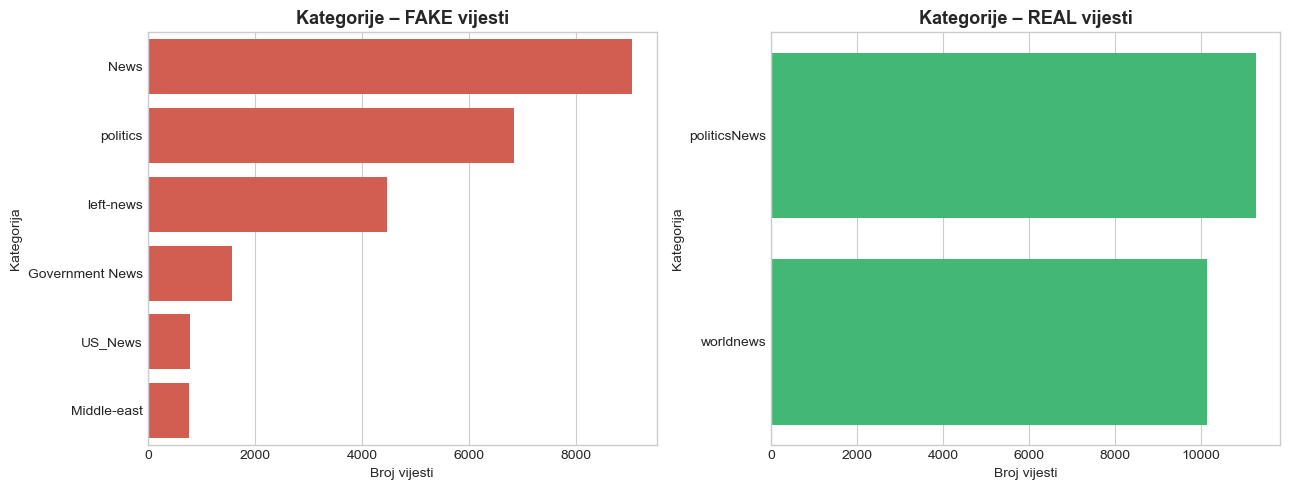

In [6]:
#  Distribucija po kategorijama (subject)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, label in zip(axes, ['fake', 'real']):
    subset = df[df['label'] == label]
    subj_counts = subset['subject'].value_counts()
    sns.barplot(
        x=subj_counts.values,
        y=subj_counts.index,
        ax=ax,
        color=COLORS[label]
    )
    ax.set_title(f'Kategorije – {label.upper()} vijesti', fontsize=13, fontweight='bold')
    ax.set_xlabel('Broj vijesti'); ax.set_ylabel('Kategorija')

plt.tight_layout()
plt.show()

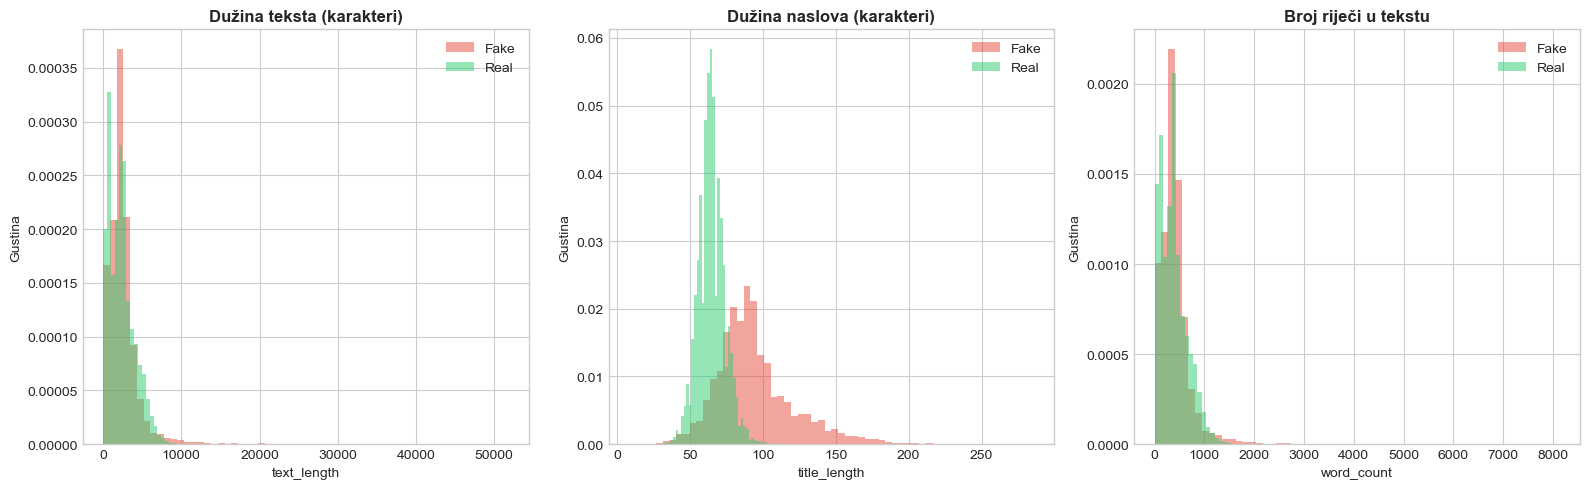

Prosječna dužina teksta po klasama:
       text_length  word_count
label                         
fake        2547.4       423.2
real        2383.3       385.6


In [7]:
# --- Dužina teksta po klasama ---
df['text_length']  = df['text'].str.len()
df['title_length'] = df['title'].str.len()
df['word_count']   = df['text'].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, title in zip(
    axes,
    ['text_length', 'title_length', 'word_count'],
    ['Dužina teksta (karakteri)', 'Dužina naslova (karakteri)', 'Broj riječi u tekstu']
):
    for label in ['fake', 'real']:
        subset = df[df['label'] == label][col]
        ax.hist(subset, bins=60, alpha=0.5, color=COLORS[label], label=label.capitalize(), density=True)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(col); ax.set_ylabel('Gustina')
    ax.legend()

plt.tight_layout()
plt.show()

print('Prosječna dužina teksta po klasama:')
print(df.groupby('label')[['text_length', 'word_count']].mean().round(1))

## 4. Čišćenje podataka

In [8]:
# Uklanjanje duplikata
before = len(df)
df = df.drop_duplicates(subset=['text'])
print(f'Uklonjeni duplikati: {before - len(df)}')

# Uklanjanje previše kratkih tekstova (vjerovatno prazni ili nečitljivi)
df = df[df['text'].str.len() > 100]
df = df[df['title'].str.len() > 5]

df = df.reset_index(drop=True)
print(f'✅ Broj zapisa nakon čišćenja: {len(df):,}')

Uklonjeni duplikati: 6252
✅ Broj zapisa nakon čišćenja: 38,343


## 5. Predobrada teksta (Text Preprocessing)

In [9]:
STOP_WORDS  = set(stopwords.words('english'))
lemmatizer  = WordNetLemmatizer()

def clean_text(text):
    """Čisti i normalizuje tekst vijesti."""
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)     # linkovi
    text = re.sub(r'\(reuters\)|reuters', '', text)           # Reuters tag
    text = re.sub(r'[^a-zA-Z\s]', '', text)                  # specijalni znakovi
    words = text.split()
    words = [w for w in words if w not in STOP_WORDS and len(w) > 2]
    words = [lemmatizer.lemmatize(w) for w in words]
    return ' '.join(words)

print('Čišćenje teksta... (može potrajati 1-2 minute)')
df['clean_text'] = df['text'].apply(clean_text)
print('✅ Predobrada završena.')

print('\nPrimjer originalnog teksta:')
print(df['text'].iloc[0][:300])
print('\nPrimjer očišćenog teksta:')
print(df['clean_text'].iloc[0][:300])

Čišćenje teksta... (može potrajati 1-2 minute)
✅ Predobrada završena.

Primjer originalnog teksta:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on Pres

Primjer očišćenog teksta:
century wire say ben stein reputable professor pepperdine university also hollywood fame appearing show film ferris bueller day made provocative statement judge jeanine pirro show recently discussing halt imposed president trump executive order travel stein referred judgement circuit court washingto


## 6. Analiza teksta – Word Cloud i najčešće riječi

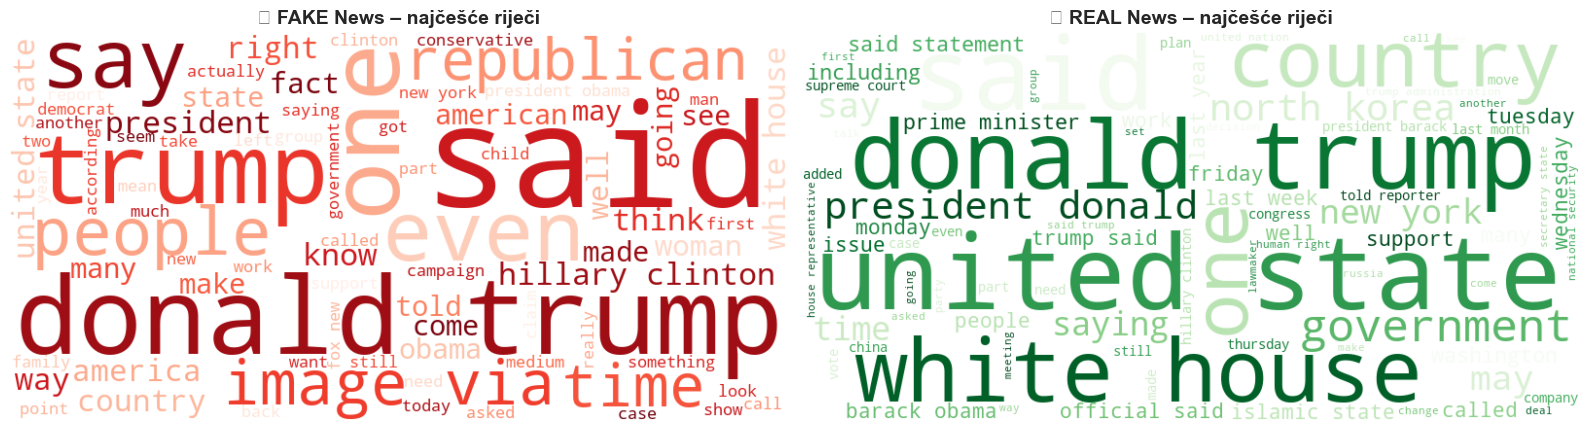

In [10]:
# Generisanje Word Cloud vizualizacija
fake_text = ' '.join(df[df['label'] == 'fake']['clean_text'])
real_text = ' '.join(df[df['label'] == 'real']['clean_text'])

wc_fake = WordCloud(
    width=800, height=400, background_color='white',
    colormap='Reds', max_words=80
).generate(fake_text)

wc_real = WordCloud(
    width=800, height=400, background_color='white',
    colormap='Greens', max_words=80
).generate(real_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(wc_fake, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('🔴 FAKE News – najčešće riječi', fontsize=14, fontweight='bold')
axes[1].imshow(wc_real, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('🟢 REAL News – najčešće riječi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

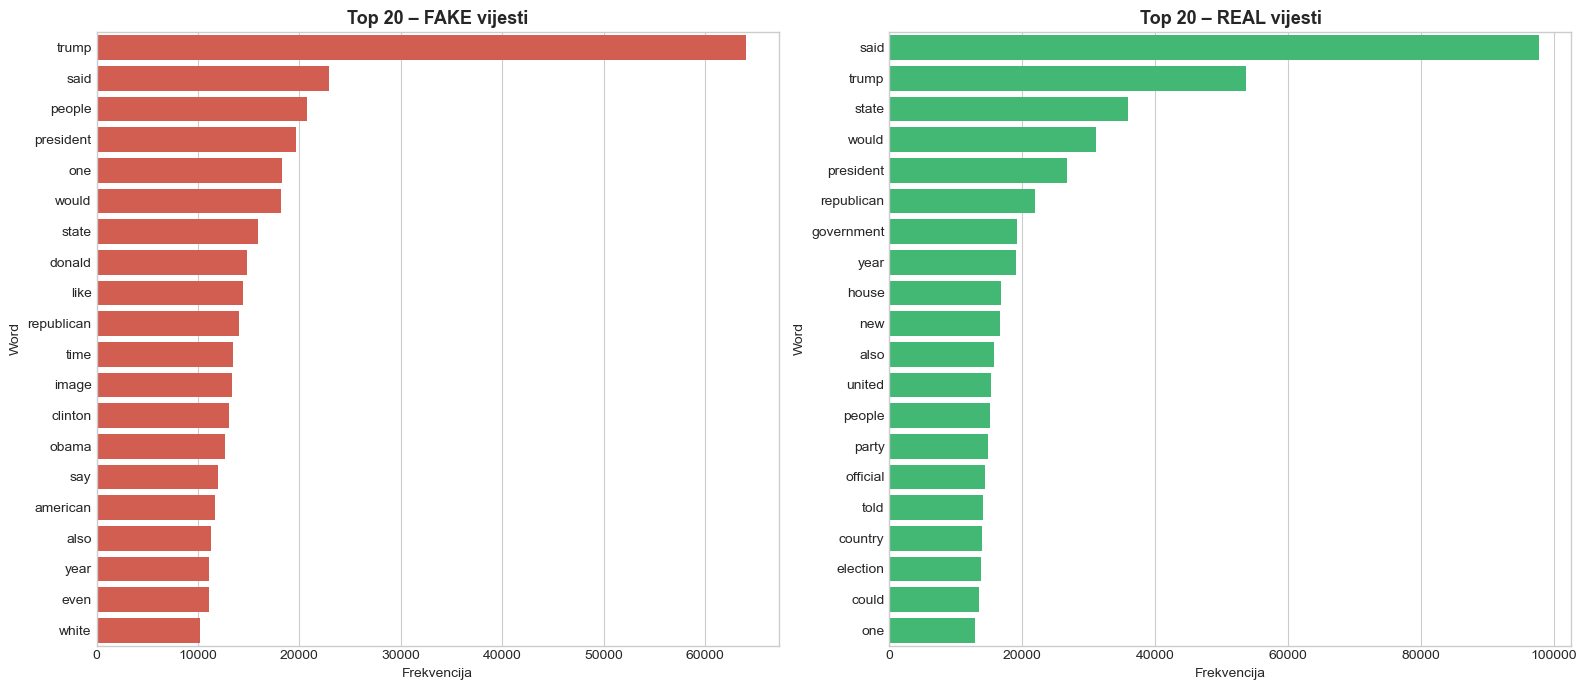

In [11]:
# Top 20 najčešćih riječi – poređenje fake vs real
def top_words(text, n=20):
    return Counter(text.split()).most_common(n)

fake_top = pd.DataFrame(top_words(fake_text), columns=['Word', 'Count'])
real_top = pd.DataFrame(top_words(real_text), columns=['Word', 'Count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=fake_top, x='Count', y='Word', ax=axes[0], color=COLORS['fake'])
axes[0].set_title('Top 20 – FAKE vijesti', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Frekvencija')

sns.barplot(data=real_top, x='Count', y='Word', ax=axes[1], color=COLORS['real'])
axes[1].set_title('Top 20 – REAL vijesti', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Frekvencija')

plt.tight_layout()
plt.show()

## 7. TF-IDF Vektorizacija i priprema podataka

In [12]:
# Koristimo clean_text za modelovanje i stratificirani split
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y       # osigurava istu distribuciju klasa u trainu i testu
)

print(f'Train set: {len(X_train):,} vijesti')
print(f'Test set:  {len(X_test):,} vijesti')
print(f'\nDistribucija u train setu:\n{y_train.value_counts()}')
print(f'\nDistribucija u test setu:\n{y_test.value_counts()}')

Train set: 30,674 vijesti
Test set:  7,669 vijesti

Distribucija u train setu:
label
real    16953
fake    13721
Name: count, dtype: int64

Distribucija u test setu:
label
real    4238
fake    3431
Name: count, dtype: int64


In [13]:
# TF-IDF sa unigramima i bigramima – hvata i fraze
vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),      # unigrami i bigrami
    min_df=3,                # ignoruj rijetke pojmove (< 3 dokumenta)
    sublinear_tf=True        # log skaliranje TF vrijednosti
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec  = vectorizer.transform(X_test)

print(f'Oblik TF-IDF matrice (train): {X_train_vec.shape}')
print(f'Broj featura (n-grama): {X_train_vec.shape[1]:,}')

Oblik TF-IDF matrice (train): (30674, 30000)
Broj featura (n-grama): 30,000


## 8. Treniranje modela

In [14]:
# Pomoćna funkcija za evaluaciju svakog modela
def evaluate_model(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    print(f'\n{'='*50}')
    print(f'  {name}')
    print(f'{'='*50}')
    print(f'  Accuracy : {acc*100:.2f}%')
    if auc:
        print(f'  ROC-AUC  : {auc:.4f}')
    print()
    print(classification_report(y_true, y_pred))
    return acc, auc

### 8.1 Logistic Regression

In [15]:
lr_model = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
lr_model.fit(X_train_vec, y_train)

y_pred_lr = lr_model.predict(X_test_vec)
y_prob_lr = lr_model.predict_proba(X_test_vec)[:, 1]

acc_lr, auc_lr = evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr)


  Logistic Regression
  Accuracy : 98.40%
  ROC-AUC  : 0.9985

              precision    recall  f1-score   support

        fake       0.99      0.97      0.98      3431
        real       0.98      0.99      0.99      4238

    accuracy                           0.98      7669
   macro avg       0.98      0.98      0.98      7669
weighted avg       0.98      0.98      0.98      7669



### 8.2 Naive Bayes

In [16]:
nb_model = MultinomialNB(alpha=0.1)   # alpha=0.1: blagi Laplace smoothing
nb_model.fit(X_train_vec, y_train)

y_pred_nb = nb_model.predict(X_test_vec)
y_prob_nb = nb_model.predict_proba(X_test_vec)[:, 1]

acc_nb, auc_nb = evaluate_model('Naive Bayes', y_test, y_pred_nb, y_prob_nb)


  Naive Bayes
  Accuracy : 95.58%
  ROC-AUC  : 0.9901

              precision    recall  f1-score   support

        fake       0.95      0.95      0.95      3431
        real       0.96      0.96      0.96      4238

    accuracy                           0.96      7669
   macro avg       0.96      0.96      0.96      7669
weighted avg       0.96      0.96      0.96      7669



### 8.3 Random Forest

In [17]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=30,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_vec, y_train)

y_pred_rf = rf_model.predict(X_test_vec)
y_prob_rf = rf_model.predict_proba(X_test_vec)[:, 1]

acc_rf, auc_rf = evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf)


  Random Forest
  Accuracy : 96.49%
  ROC-AUC  : 0.9961

              precision    recall  f1-score   support

        fake       0.98      0.94      0.96      3431
        real       0.95      0.99      0.97      4238

    accuracy                           0.96      7669
   macro avg       0.97      0.96      0.96      7669
weighted avg       0.97      0.96      0.96      7669



## 9. Poređenje i vizualizacija rezultata

In [18]:
# Tabela rezultata
results_df = pd.DataFrame({
    'Model'       : ['Logistic Regression', 'Naive Bayes', 'Random Forest'],
    'Accuracy (%)': [round(acc_lr*100, 2), round(acc_nb*100, 2), round(acc_rf*100, 2)],
    'ROC-AUC'     : [round(auc_lr, 4), round(auc_nb, 4), round(auc_rf, 4)]
}).sort_values('Accuracy (%)', ascending=False).reset_index(drop=True)

print('=== Poređenje modela ===')
print(results_df.to_string(index=False))

=== Poređenje modela ===
              Model  Accuracy (%)  ROC-AUC
Logistic Regression         98.40   0.9985
      Random Forest         96.49   0.9961
        Naive Bayes         95.58   0.9901


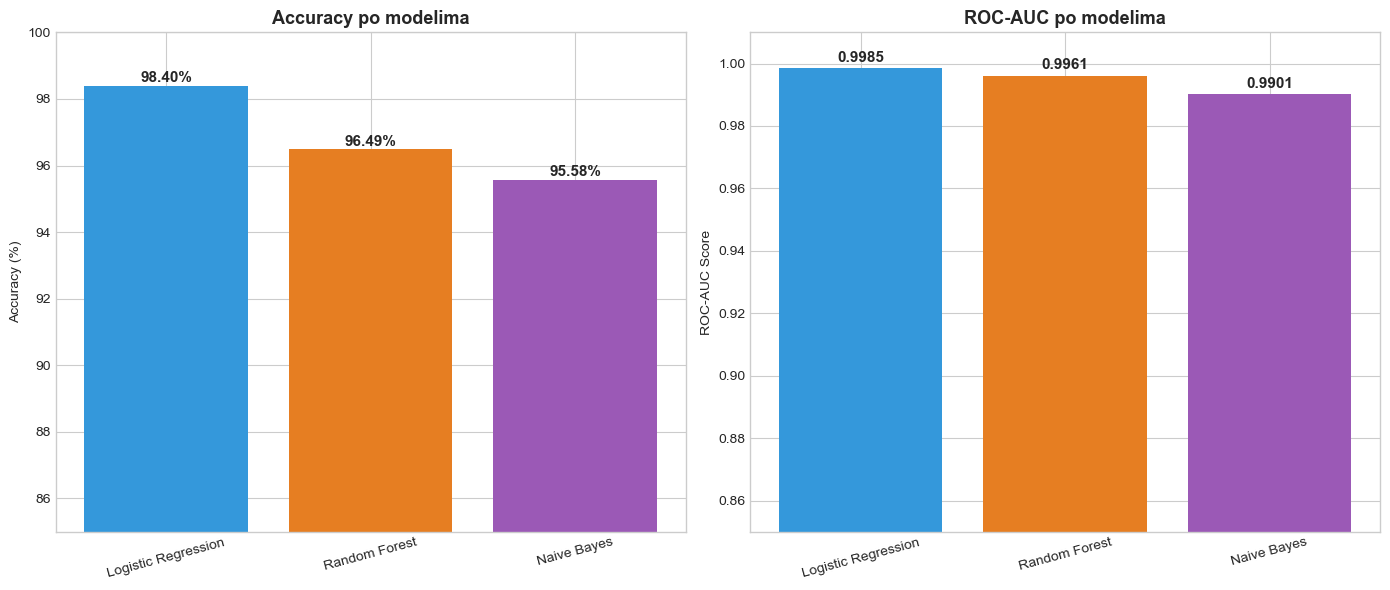

In [19]:
# Bar chart poređenja
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

palette = ['#3498db', '#e67e22', '#9b59b6']

# Accuracy
bars = axes[0].bar(results_df['Model'], results_df['Accuracy (%)'], color=palette)
axes[0].set_title('Accuracy po modelima', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(85, 100)
axes[0].tick_params(axis='x', rotation=15)
for bar, val in zip(bars, results_df['Accuracy (%)']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

# ROC-AUC
bars2 = axes[1].bar(results_df['Model'], results_df['ROC-AUC'], color=palette)
axes[1].set_title('ROC-AUC po modelima', fontsize=13, fontweight='bold')
axes[1].set_ylabel('ROC-AUC Score')
axes[1].set_ylim(0.85, 1.01)
axes[1].tick_params(axis='x', rotation=15)
for bar, val in zip(bars2, results_df['ROC-AUC']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

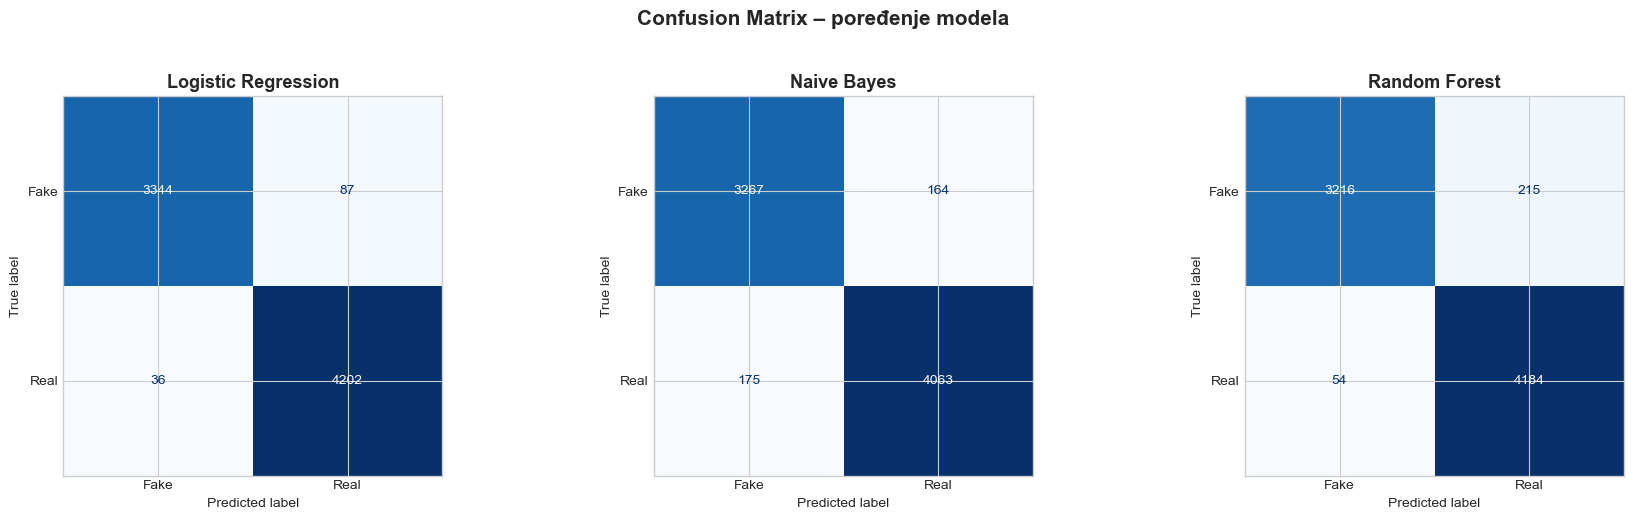

In [20]:
# Confusion Matrix – sva tri modela
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_info = [
    ('Logistic Regression', y_pred_lr),
    ('Naive Bayes',         y_pred_nb),
    ('Random Forest',       y_pred_rf)
]

for ax, (name, y_pred) in zip(axes, models_info):
    cm   = confusion_matrix(y_test, y_pred, labels=['fake', 'real'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fake', 'Real'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=13, fontweight='bold')

plt.suptitle('Confusion Matrix – poređenje modela', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

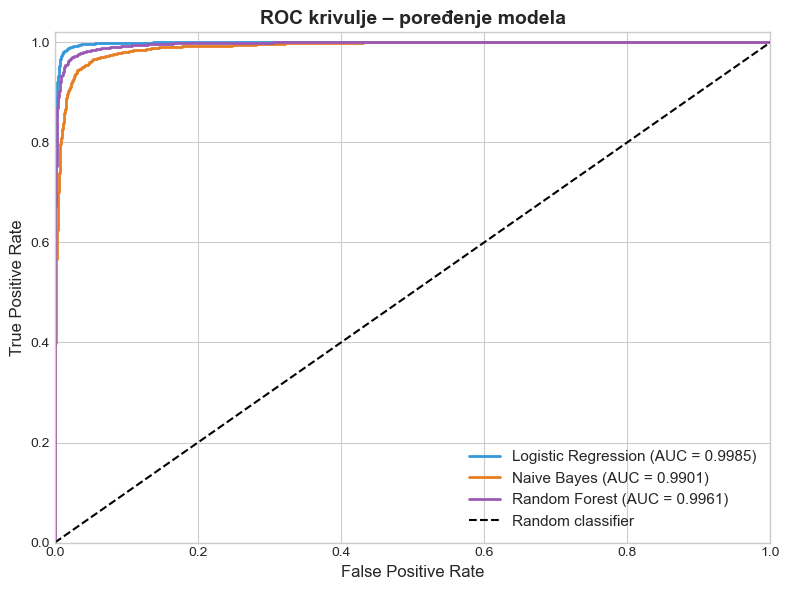

In [21]:
# ROC krivulje
plt.figure(figsize=(8, 6))

label_binary = (y_test == 'real').astype(int)

for name, y_prob, color in [
    ('Logistic Regression', y_prob_lr, '#3498db'),
    ('Naive Bayes',         y_prob_nb, '#e67e22'),
    ('Random Forest',       y_prob_rf, '#9b59b6')
]:
    fpr, tpr, _ = roc_curve(label_binary, y_prob)
    auc_val = roc_auc_score(label_binary, y_prob)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random classifier')
plt.xlim([0, 1]); plt.ylim([0, 1.02])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC krivulje – poređenje modela', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

## 10. Analiza grešaka

In [22]:
# Primjeri pogrešno klasifikovanih vijesti (Logistic Regression)
test_df = X_test.reset_index(drop=True).to_frame()
test_df['true_label'] = y_test.reset_index(drop=True)
test_df['pred_label'] = y_pred_lr
test_df['original_text'] = df.loc[X_test.index, 'text'].reset_index(drop=True).values

misclassified = test_df[test_df['true_label'] != test_df['pred_label']]
print(f'Pogrešno klasifikovano: {len(misclassified)} od {len(test_df)} ({len(misclassified)/len(test_df)*100:.2f}%)')
print(f'\nRaspored grešaka:')
print(misclassified.groupby(['true_label', 'pred_label']).size())

print('\n=== Primjer FAKE → pogrešno klasifikovano kao REAL ===')
fn = misclassified[(misclassified['true_label'] == 'fake') & (misclassified['pred_label'] == 'real')]
if len(fn) > 0:
    print(fn['original_text'].iloc[0][:400])

print('\n=== Primjer REAL → pogrešno klasifikovano kao FAKE ===')
fp = misclassified[(misclassified['true_label'] == 'real') & (misclassified['pred_label'] == 'fake')]
if len(fp) > 0:
    print(fp['original_text'].iloc[0][:400])

Pogrešno klasifikovano: 123 od 7669 (1.60%)

Raspored grešaka:
true_label  pred_label
fake        real          87
real        fake          36
dtype: int64

=== Primjer FAKE → pogrešno klasifikovano kao REAL ===
Priorities priorities Arizona Sen. John McCain wants a subpoena issued immediately for the head of the Environmental Protection Agency to attend a hearing in his home state on the Colorado mine disaster the agency caused last year.The August disaster caused an uncontrolled rupture of an abandoned gold mine that caused 3 million gallons of toxic sludge to spill into the Animas River, which sullied 

=== Primjer REAL → pogrešno klasifikovano kao FAKE ===
(Reuters) - Delegates at both the Republican and the Democratic conventions sported outrageous outfits - but the views from their respective gatherings were a study in contrast. Republican National Convention delegates in Cleveland last week embraced a freewheeling, policy-light lineup, reveling in messages of salvation from Rep

## 11. Testiranje na novim primjerima

In [23]:
def predict_news(text, model=lr_model, label='Logistic Regression'):
    """Predviđa da li je vijest fake ili real i prikazuje vjerovatnoće."""
    cleaned = clean_text(text)
    vec     = vectorizer.transform([cleaned])
    pred    = model.predict(vec)[0]
    probs   = model.predict_proba(vec)[0]
    classes = model.classes_
    prob_d  = dict(zip(classes, probs))

    emoji = '🔴' if pred == 'fake' else '🟢'
    print(f'[{label}]')
    print(f'Tekst: "{text[:120]}..."')
    print(f'Predikcija: {emoji} {pred.upper()}')
    print(f'Vjerovatnoće → fake: {prob_d["fake"]:.1%}  |  real: {prob_d["real"]:.1%}')
    print()

# Test primjeri
examples = [
    "President Biden signs new executive order on climate change, requiring federal agencies to cut emissions.",
    "BREAKING: Scientists have confirmed that 5G towers are spreading COVID-19! Government is hiding the truth from the public!",
    "The Federal Reserve raised interest rates by 0.25% following the latest inflation data from the Bureau of Labor Statistics.",
    "SHOCKING: NASA admits moon landing was FAKE, admits all astronauts were actors paid by Hollywood!"
]

print('=== Testiranje na novim primjerima ===')
for ex in examples:
    predict_news(ex)

=== Testiranje na novim primjerima ===
[Logistic Regression]
Tekst: "President Biden signs new executive order on climate change, requiring federal agencies to cut emissions...."
Predikcija: 🔴 FAKE
Vjerovatnoće → fake: 50.1%  |  real: 49.9%

[Logistic Regression]
Tekst: "BREAKING: Scientists have confirmed that 5G towers are spreading COVID-19! Government is hiding the truth from the publi..."
Predikcija: 🔴 FAKE
Vjerovatnoće → fake: 74.1%  |  real: 25.9%

[Logistic Regression]
Tekst: "The Federal Reserve raised interest rates by 0.25% following the latest inflation data from the Bureau of Labor Statisti..."
Predikcija: 🟢 REAL
Vjerovatnoće → fake: 33.1%  |  real: 66.9%

[Logistic Regression]
Tekst: "SHOCKING: NASA admits moon landing was FAKE, admits all astronauts were actors paid by Hollywood!..."
Predikcija: 🔴 FAKE
Vjerovatnoće → fake: 84.5%  |  real: 15.5%



## 12. Zaključak

### Rezultati

| Model | Accuracy | ROC-AUC |
|---|---|---|
| Logistic Regression | 98.40% | 0.9985 |
| Naive Bayes | 95.58% | 0.9901 |
| Random Forest | 96.49% | 0.9961 |

### Ključni zaključci

- **Logistic Regression** postiže odlične rezultate i najbrže trenira — idealan za NLP klasifikaciju
- **TF-IDF** s bigramima i `sublinear_tf` je ključan za dobre rezultate
- **Fake vijesti** i **real vijesti** koriste vidljivo različit rječnik, što modelu olakšava klasifikaciju
- **Preprocessing** (lemmatizacija, uklanjanje stopwords, linkova) poboljšava kvalitet featura
- Greške su uglavnom na **graničnim slučajevima** – vijesti koje koriste formalni jezik ali lažan sadržaj